# 05 — XGBoost
### Telco Customer Churn Prediction

XGBoost is a widely used gradient-boosting library. It is evaluated to check whether a different boosting implementation, with its own regularisation options, changes the conclusion reached with HistGradientBoosting.

**Shared protocol** (identical in notebooks 01–06):
- Same training set (3,944 customers) and same 5 stratified folds (`random_state = 34`).
- Same preprocessing (`FINAL_PREP_CONFIG` from notebook 00): binary add-ons, one-hot `InternetService` and `Contract`, binary `Dependents`/`PaperlessBilling`, standardised `log(1 + tenure)` and `MonthlyCharges`.
- Same tuning procedure: **nested cross-validation** (inner 5-fold grid search, outer 5-fold evaluation), scored by PR-AUC.
- Unweighted classes; class imbalance is handled at the decision threshold (notebook 08) and examined in notebook 07.
- The test set is **not used**. The nested out-of-fold predictions saved at the end are used for comparison and threshold selection in notebook 08.

## 1. How the Algorithm Works

XGBoost is gradient boosting with a **second-order** approximation of the loss: each tree is fitted using both the gradient and the curvature (Hessian) of the log-loss.

It adds explicit regularisation to the tree-building objective:
- an L2 penalty on leaf weights (`reg_lambda`);
- a minimum Hessian weight per child (`min_child_weight`), roughly a minimum leaf size;
- row and column subsampling.

Trees grow **level-wise** to a fixed `max_depth`.

**Differences from HistGradientBoosting:** both use histogram-based split finding here (`tree_method="hist"`). XGBoost limits *depth*, whereas HistGradientBoosting limits *leaf count*, and XGBoost offers more regularisation controls and subsampling.

## 2. Relevance, Assumptions and Limitations

- **Relevance:** a common benchmark for tabular classification. Including it checks that the boosting result is not specific to one implementation.
- **Limitations:**
  - low interpretability;
  - many hyperparameters;
  - an extra dependency (`xgboost`) for deployment.

## 3. Setup

In [1]:
import sys
from pathlib import Path

# Make the project's shared src/ package importable, wherever Jupyter was started
PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "data_preprocessing.py").exists())
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.base import clone
from sklearn.metrics import average_precision_score, precision_recall_curve
from xgboost import XGBClassifier
from src.data_preprocessing import FINAL_PREP_CONFIG, RANDOM_STATE, build_pipeline, load_raw_data, split_train_test
from src.evaluation import (cv_scores, final_search, fold_metrics, mean_std_table, nested_summary_row, run_nested_cv,
                            save_results, summarise_cv)
from src.visualization import plot_confusion, plot_permutation_importance, plot_reliability, save_figure, set_style

set_style()
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", None)

df = load_raw_data()                                       # validated raw data (read-only)
X_train, X_test, y_train, y_test = split_train_test(df)   # the project's single stratified 80/20 split
del X_test, y_test                                        # the test set is not used in this notebook
print(f"Training set: {X_train.shape[0]:,} customers, {int(y_train.sum()):,} churners ({y_train.mean():.2%})")
print("Preprocessing configuration (from notebook 00):", FINAL_PREP_CONFIG)

Training set: 3,944 customers, 1,053 churners (26.70%)
Preprocessing configuration (from notebook 00): {'contract': 'onehot', 'addons': 'binary', 'tenure': 'log'}


In [2]:
MODEL_NAME = "XGBoost"
SLUG = "05_xgboost"
INTERPRETABILITY_RANK = 5  # 1 = most interpretable

## 4. Preprocessing Pipeline

The shared pipeline is used unchanged. Its output is a numeric matrix, which XGBoost accepts directly.

In [3]:
ESTIMATOR = XGBClassifier(n_estimators=300, subsample=0.8, colsample_bytree=0.8, tree_method="hist", eval_metric="logloss", random_state=RANDOM_STATE, n_jobs=1)


pipeline = build_pipeline(ESTIMATOR, **FINAL_PREP_CONFIG)
print("Pipeline steps:", [name for name, _ in pipeline.steps])
print("Transformers:", [(name, cols) for name, _, cols in pipeline.named_steps["preprocess"].transformers])
print("Model:", ESTIMATOR)

Pipeline steps: ['preprocess', 'model']
Transformers: [('binary', ['Dependents', 'PaperlessBilling']), ('addons', ['OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport']), ('internet', ['InternetService']), ('contract', ['Contract']), ('tenure_log', ['tenure']), ('numeric', ['MonthlyCharges'])]
Model: XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=0.8, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=None, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=None, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              m

## 5. Baseline Configuration

The baseline uses XGBoost's defaults (learning rate 0.3, `max_depth` 6, 100 trees, no subsampling).

In [4]:
BASELINE_ESTIMATOR = XGBClassifier(eval_metric="logloss", random_state=RANDOM_STATE, n_jobs=1)


baseline_raw = cv_scores(build_pipeline(BASELINE_ESTIMATOR, **FINAL_PREP_CONFIG), X_train, y_train)
baseline = summarise_cv(baseline_raw)
display(mean_std_table(pd.DataFrame([baseline], index=["Baseline (5-fold CV, threshold 0.5)"])))
gap = {m: baseline[f"{m} train"] - baseline[f"{m} mean"] for m in ["F1", "ROC-AUC", "PR-AUC"]}
print("Train - validation gap:", {k: round(v, 3) for k, v in gap.items()})

,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
"Baseline (5-fold CV, threshold 0.5)",0.781 ± 0.013,0.606 ± 0.030,0.516 ± 0.025,0.557 ± 0.023,0.822 ± 0.017,0.608 ± 0.028


Train - validation gap: {'F1': np.float64(0.306), 'ROC-AUC': np.float64(0.159), 'PR-AUC': np.float64(0.337)}


**Interpretation.**
- XGBoost's defaults (learning rate 0.3, depth 6) overfit: validation PR-AUC **0.608**, ROC-AUC 0.822, and a training-fold PR-AUC 0.337 higher.
- Like the other ensembles, it needs strong regularisation on 3,944 customers.

## 6. Hyperparameter Tuning Methodology


Hyperparameters are tuned with **nested cross-validation**:
- the 5 outer folds hold out 20% of the training set in turn;
- on the other 80%, a full grid search with its own inner 5-fold CV chooses the configuration;
- the chosen configuration, refitted on that 80%, predicts the held-out outer fold.

The outer-fold labels never influence tuning, so the resulting out-of-fold (OOF) probabilities are honest estimates of how the *whole hyperparameter-tuning procedure* performs on unseen customers. (The preprocessing configuration was fixed beforehand in notebook 00 using the same training folds; notebook 08, Section 6 shows that re-selecting it inside the nested loop changes the estimate only marginally.) A simpler "tune on everything, then cross-validate" design would reuse the same labels for selection and evaluation, which makes the estimates optimistic.

The search space (48 configurations) is comparable to HistGradientBoosting's (36), so neither boosting library is disadvantaged by a smaller search.

| Hyperparameter | Values | Role |
|---|---|---|
| `n_estimators` | 300 (fixed) | Number of boosting rounds |
| `subsample`, `colsample_bytree` | 0.8 (fixed) | Row/column subsampling for regularisation |
| `learning_rate` | 0.01, 0.03, 0.1 | Shrinkage of each tree (range extended after a first run selected the boundary value) |
| `max_depth` | 1, 2, 3, 4 | Depth of each tree (interaction order; depth 1 = additive stumps) (range extended after a first run selected the boundary value) |
| `min_child_weight` | 1, 5 | Minimum Hessian weight per leaf |
| `reg_lambda` | 1, 5 | L2 penalty on leaf weights |

In [5]:
PARAM_GRID = {"model__learning_rate": [0.01, 0.03, 0.1], "model__max_depth": [1, 2, 3, 4], "model__min_child_weight": [1, 5], "model__reg_lambda": [1.0, 5.0]}


n_configurations = int(np.prod([len(v) for v in PARAM_GRID.values()]))
print(f"{n_configurations} configurations x 5 inner folds x 5 outer folds = {n_configurations * 25} fits "
      f"(+ {5} refits) in the nested CV")

48 configurations x 5 inner folds x 5 outer folds = 1200 fits (+ 5 refits) in the nested CV


## 7. Nested Cross-Validation Results

In [6]:
nested = run_nested_cv(ESTIMATOR, PARAM_GRID, X_train, y_train, FINAL_PREP_CONFIG, compute_importance=True)
print(f"Nested CV wall time: {nested['seconds']:.1f} s\n")
display(nested["folds"].round(4))
print("Mean ± std over the 5 outer folds (accuracy, precision, recall and F1 at the reference threshold 0.5):")
display(pd.DataFrame([nested_summary_row(nested)], index=[MODEL_NAME]))
print("Hyperparameters chosen by the inner search in each outer fold:")
for fold, params in enumerate(nested["params"], start=1):
    print(f"  fold {fold}: {params}")

Nested CV wall time: 87.3 s



,accuracy,precision,recall,f1,roc_auc,pr_auc,brier,log_loss
fold,,,,,,,,
1,0.8086,0.6596,0.5877,0.6216,0.8469,0.6423,0.1381,0.4161
2,0.7997,0.6853,0.4645,0.5537,0.8648,0.7062,0.1303,0.4040
3,0.7858,0.6129,0.5403,0.5743,0.8241,0.6585,0.1434,0.4455
4,0.7997,0.6667,0.4952,0.5683,0.8438,0.6597,0.1353,0.4179
5,0.8008,0.6934,0.4524,0.5476,0.8526,0.6609,0.1350,0.4160


Mean ± std over the 5 outer folds (accuracy, precision, recall and F1 at the reference threshold 0.5):


,PR-AUC,ROC-AUC,Brier score,Accuracy,Precision,Recall,F1
XGBoost,0.666 ± 0.021,0.846 ± 0.013,0.136 ± 0.004,0.799 ± 0.007,0.664 ± 0.028,0.508 ± 0.050,0.573 ± 0.026


Hyperparameters chosen by the inner search in each outer fold:
  fold 1: {'learning_rate': 0.1, 'max_depth': 1, 'min_child_weight': 1, 'reg_lambda': 5.0}
  fold 2: {'learning_rate': 0.01, 'max_depth': 4, 'min_child_weight': 1, 'reg_lambda': 1.0}
  fold 3: {'learning_rate': 0.1, 'max_depth': 1, 'min_child_weight': 1, 'reg_lambda': 1.0}
  fold 4: {'learning_rate': 0.03, 'max_depth': 2, 'min_child_weight': 5, 'reg_lambda': 1.0}
  fold 5: {'learning_rate': 0.01, 'max_depth': 4, 'min_child_weight': 1, 'reg_lambda': 5.0}


**Interpretation.**
- Nested **PR-AUC 0.666 ± 0.021** and **ROC-AUC 0.846 ± 0.013**: the best of the boosting libraries, and equal to Logistic Regression (difference 0.0006).
- **Boundary check:** the first run chose learning rate 0.03 and depth 2 on the grid edge, so the grid was extended to 0.01 and depth 1. The inner search now chooses depth 1 (additive stumps), 2 and 4, with learning rates from 0.01 to 0.1, across folds. There is no consistent optimum at an edge: the surface is flat.
- Depth-1 trees chosen in two folds are a purely **additive** model with no interactions. That is again consistent with the linear model being sufficient.
- XGBoost is the slowest model to tune (about 81 s for the nested CV).

## 8. Final Hyperparameters

The same grid search is run once on the full training set. Its refitted pipeline is this algorithm's final candidate, which notebook 09 evaluates if it is selected. Comparing the best search score with the nested estimate shows the optimism of a non-nested search.

In [7]:
search = final_search(ESTIMATOR, PARAM_GRID, X_train, y_train, FINAL_PREP_CONFIG)
final_params = {k.replace("model__", ""): v for k, v in search.best_params_.items()}
final_summary = pd.Series({
    "best hyperparameters": final_params,
    "search CV PR-AUC (best of grid)": round(search.best_score_, 4),
    "nested CV PR-AUC": round(nested["folds"]["pr_auc"].mean(), 4),
    "optimism of the search score": round(search.best_score_ - nested["folds"]["pr_auc"].mean(), 4),
    "train-fold PR-AUC of best configuration": round(search.cv_results_["mean_train_score"][search.best_index_], 4),
})
display(final_summary.to_frame("value"))

,value
best hyperparameters,"{'learning_rate': 0.01, 'max_depth': 4, 'min_child_weight': 5, 'reg_lambda': 1.0}"
search CV PR-AUC (best of grid),0.6688
nested CV PR-AUC,0.6655
optimism of the search score,0.0032
train-fold PR-AUC of best configuration,0.7049


## 9. Diagnostics (Nested Out-of-Fold Predictions)

The confusion matrix uses the reference threshold of 0.5 only; the operating threshold is chosen in notebook 08. The reliability diagram checks whether predicted probabilities match observed churn rates (**calibration**), and the precision-recall curve shows the ranking quality across all thresholds (**discrimination**).

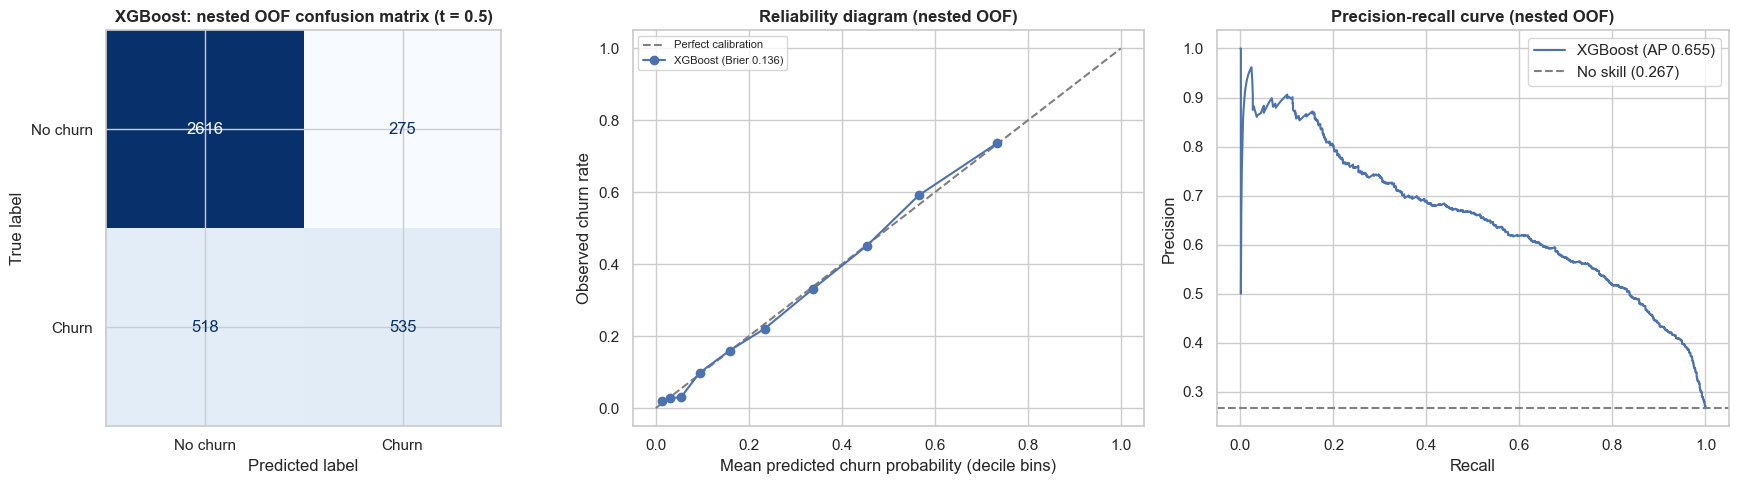

In [8]:
oof = nested["oof"]
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
plot_confusion(axes[0], y_train, (oof >= 0.5).astype(int), f"{MODEL_NAME}: nested OOF confusion matrix (t = 0.5)")
plot_reliability(axes[1], y_train, {MODEL_NAME: oof}, "Reliability diagram (nested OOF)")
prec, rec, _ = precision_recall_curve(y_train, oof)
axes[2].plot(rec, prec, label=f"{MODEL_NAME} (AP {average_precision_score(y_train, oof):.3f})")
axes[2].axhline(y_train.mean(), linestyle="--", color="gray", label=f"No skill ({y_train.mean():.3f})")
axes[2].set_title("Precision-recall curve (nested OOF)")
axes[2].set_xlabel("Recall")
axes[2].set_ylabel("Precision")
axes[2].legend()
plt.tight_layout()
save_figure(fig, f"{SLUG}_diagnostics")
plt.show()

**Interpretation.**
- **At t = 0.5:** 535 churners caught, 518 missed, 275 non-churners flagged; almost identical to Logistic Regression.
- **Calibration** is good (Brier 0.136).
- **Precision-recall curve:** pooled AP 0.655.

## 10. Model Interpretation

**Permutation importance** is the drop in PR-AUC when one original feature's values are shuffled. It is computed inside the nested CV, on each outer validation fold, for the model tuned and fitted without that fold, so it inherits no selection leakage. Shuffling one of two features that share information understates both. Importance describes what the *model* relies on; it is not a causal effect.

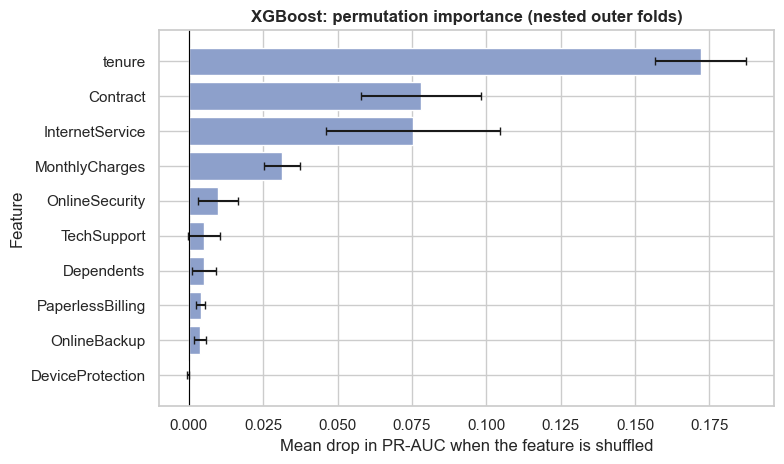

,mean,std
feature,,
tenure,0.1720,0.0153
Contract,0.0781,0.0202
InternetService,0.0754,0.0291
MonthlyCharges,0.0313,0.0060
OnlineSecurity,0.0099,0.0068
TechSupport,0.0051,0.0055
Dependents,0.0051,0.0040
PaperlessBilling,0.0040,0.0015
OnlineBackup,0.0037,0.0021


In [9]:
fig, ax = plt.subplots(figsize=(8, 4.8))
perm_summary = plot_permutation_importance(ax, nested["importance"],
                                           f"{MODEL_NAME}: permutation importance (nested outer folds)")
plt.tight_layout()
save_figure(fig, f"{SLUG}_permutation_importance")
plt.show()
display(perm_summary.sort_values("mean", ascending=False).round(4))

**Interpretation.**
- `tenure` (0.172), `Contract` (0.078), `InternetService` (0.075) and `MonthlyCharges` (0.031) carry almost all of the predictive information. `DeviceProtection` carries none.
- The ordering matches HistGradientBoosting's.

## 11. Strengths, Weaknesses and Conclusion

**Strengths**
- Ranking equal to Logistic Regression (nested PR-AUC 0.666).
- Good calibration.
- Rich regularisation options.

**Weaknesses**
- No gain over the simplest model.
- Opaque.
- The slowest to tune.
- An extra dependency for deployment.

**Conclusion:** XGBoost is genuinely competitive but not better. Under the project's selection rule (notebook 08), equal performance favours the interpretable model.

### Saving the training-stage results

The nested OOF predictions, fold metrics, permutation importances and the final (training-set) pipeline are stored in `reports/cv_results/` for the comparison in notebook 08.

In [10]:
payload = {
    "name": MODEL_NAME, "slug": SLUG, "oof": nested["oof"], "folds": nested["folds"], "params": nested["params"],
    "importance": nested["importance"], "seconds": nested["seconds"], "baseline": baseline,
    "final_params": final_params, "final_search_score": search.best_score_,
    "final_train_score": search.cv_results_["mean_train_score"][search.best_index_],
    "final_pipeline": search.best_estimator_, "grid": PARAM_GRID, "prep_config": FINAL_PREP_CONFIG,
    "y_index": y_train.index.to_numpy(), "interpretability_rank": INTERPRETABILITY_RANK,
}
print("Saved:", save_results(SLUG, payload).relative_to(PROJECT_ROOT))

Saved: reports\cv_results\05_xgboost.joblib
